In [193]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path


from sklearn.metrics import mean_absolute_error, mean_squared_error

In [194]:
%load_ext autoreload
%autoreload 2

from przygotowanie_danych_przepompowania import przygotuj_dane_przepompowania_z_opadami

X, y = przygotuj_dane_przepompowania_z_opadami()

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# CATBOOST

Model opadów opisuje spodziewane pompowanie w danych warunkach, a Q97 stanowi granicę alarmową 

In [195]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 156 z 5255


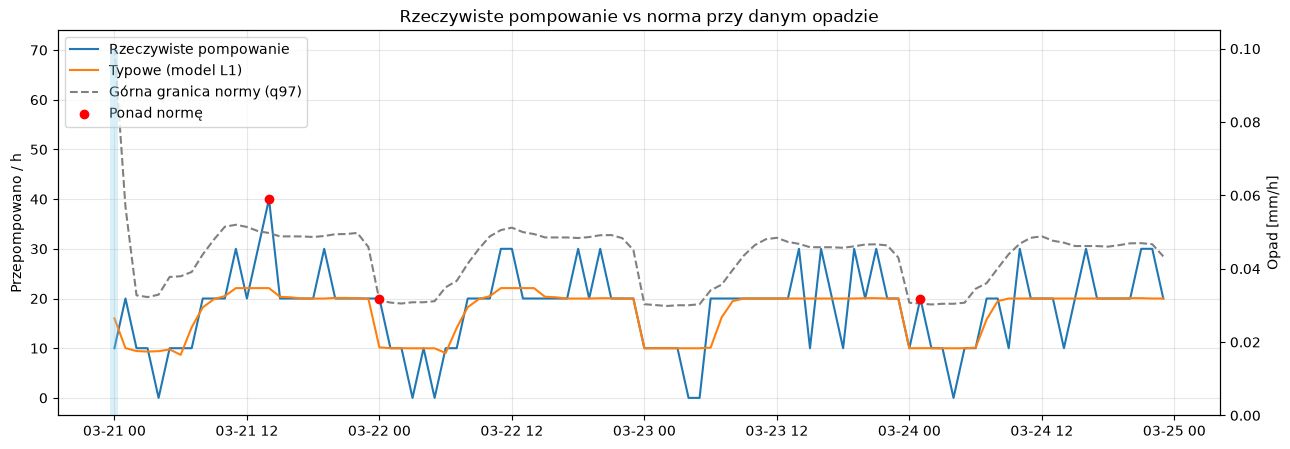

In [196]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [197]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 156
Suma nadwyżek w godzinach alarmowych: 13953.81


In [198]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało 
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2026-03-08 01:00:00,20.0,9.994279,18.931376,10.005721,1.068624,0.0,0.0
2026-03-09 09:00:00,30.0,20.000458,28.627444,9.999542,1.372556,0.0,0.0
2026-03-10 00:00:00,20.0,9.983340,19.152670,10.016660,0.847330,0.0,0.0
2026-03-11 00:00:00,20.0,9.975443,19.113295,10.024557,0.886705,0.0,0.0
2026-03-15 00:00:00,20.0,10.161024,19.635566,9.838976,0.364434,0.0,0.0
...,...,...,...,...,...,...,...
2026-09-23 17:00:00,250.0,52.652044,169.653235,197.347956,80.346765,0.1,2.6
2026-10-01 12:00:00,40.0,28.783677,38.160168,11.216323,1.839832,0.0,0.0
2026-10-04 20:00:00,40.0,29.159417,37.903495,10.840583,2.096505,0.0,0.0


In [199]:

# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 9.14
Przekroczenia Q97 TEST: 2.97 %
Liczba alarmów TEST: 156


In [200]:
from pathlib import Path
from sciezka_projektu import get_project_root
import pandas as pd

DATA_PATH = get_project_root() / "data" / "processed" / "Chorzów"
awarie = pd.read_parquet(DATA_PATH / "awarie.parquet")


In [201]:

# Przygotowanie awarii
awarie["Data_czas"] = pd.to_datetime(
    awarie["Data_czas"], errors="coerce"
)

kolumny_awarii = [
    c for c in awarie.columns
    if c not in ["Data", "Czas", "Data_czas"]
]

for c in kolumny_awarii:
    awarie[c] = pd.to_numeric(
        awarie[c].astype(str)
        .str.replace(",", ".", regex=False)
        .str.strip()
        .replace("-", np.nan),
        errors="coerce"
    )

# 0 oznacza brak aktywnej flagi
# Wykrywamy przejścia z 0 na 1
a = (
    awarie.dropna(subset=["Data_czas"])
    .set_index("Data_czas")
    .sort_index()
)

flagi = a[kolumny_awarii].fillna(0).gt(0)
starty = flagi & ~flagi.shift(1, fill_value=False)

awarie_start = (
    starty.any(axis=1)
    .resample("1h")
    .max()
    .astype("boolean")
    .fillna(False)
    .rename("start_awarii")
)

# Łączenie z wynikami CatBoosta
analiza = results_val.copy()

analiza = analiza.join(awarie_start, how="left")

analiza["start_awarii"] = (
    analiza["start_awarii"]
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)

# Sprawdzamy, czy awaria wystąpiła +/-12h od alarmu
starty_h = awarie_start.reindex(
    pd.date_range(
        analiza.index.min() - pd.Timedelta(hours=12),
        analiza.index.max() + pd.Timedelta(hours=12),
        freq="1h"
    ),
    fill_value=False
).astype(bool)

blisko = (
    starty_h
    .rolling(25, center=True, min_periods=1)
    .max()
    .astype(bool)
)

analiza["blisko_awarii_12h"] = (
    blisko.reindex(analiza.index, fill_value=False)
)

liczba_alarmow = int(analiza["alarm"].sum())

alarmy_blisko = int(
    (analiza["alarm"] & analiza["blisko_awarii_12h"]).sum()
)

print("Wszystkie godziny alarmowe:", liczba_alarmow)
print("Godziny alarmowe blisko awarii:", alarmy_blisko)
print("Godziny alarmowe bez bliskości awarii:", liczba_alarmow - alarmy_blisko)

display(
    analiza.loc[
        analiza["alarm"],
        ["nadwyzka", "start_awarii", "blisko_awarii_12h"]
    ].head(20)
)


Wszystkie godziny alarmowe: 156
Godziny alarmowe blisko awarii: 87
Godziny alarmowe bez bliskości awarii: 69


,nadwyzka,start_awarii,blisko_awarii_12h
Data_czas,,,
2026-03-08 01:00:00,10.005721,False,False
2026-03-09 09:00:00,9.999542,False,False
2026-03-10 00:00:00,10.016660,False,False
2026-03-11 00:00:00,10.024557,False,False
2026-03-15 00:00:00,9.838976,False,False
2026-03-16 09:00:00,10.017136,False,False
2026-03-18 09:00:00,9.999566,False,False
2026-03-21 14:00:00,17.910880,False,False
2026-03-22 00:00:00,9.837946,False,False


In [202]:
diag_q97 = X_test[["opad_24h"]].copy()

diag_q97["rzeczywiste"] = y_test.to_numpy()
diag_q97["q97"] = q_test

diag_q97["alarm"] = (
    diag_q97["rzeczywiste"] > diag_q97["q97"]
)

diag_q97["warunki"] = np.select(
    [
        diag_q97["opad_24h"].isna(),
        diag_q97["opad_24h"] > 0
    ],
    ["Brak danych", "Mokro"],
    default="Sucho"
)

display(
    diag_q97.groupby("warunki").agg(
        liczba_godzin=("alarm", "size"),
        liczba_alarmow=("alarm", "sum"),
        odsetek_alarmow=("alarm", "mean")
    ).assign(
        odsetek_alarmow=lambda d: d["odsetek_alarmow"] * 100
    )
)

,liczba_godzin,liczba_alarmow,odsetek_alarmow
warunki,,,
Brak danych,22,2,9.090909
Mokro,3077,79,2.567436
Sucho,2156,75,3.478664


In [203]:
kolumny_raportu = [
    "rzeczywiste",
    "prognoza",
    "q97",
    "nadwyzka",
    "ponad_q97",
    "opad",
    "opad_6h",
    "start_awarii",
    "blisko_awarii_12h"
]

raport_godzinowy = analiza.loc[
    analiza["alarm"], kolumny_raportu
].copy()

raport_godzinowy.index.name = "data_godzina"

# Sumujemy nadwyżki wyłącznie w godzinach alarmowych
analiza["nadwyzka_alarmowa"] = analiza["nadwyzka"].where(
    analiza["alarm"], 0
)

raport_dzienny = analiza.resample("1D").agg(
    godziny_alarmow=("alarm", "sum"),
    suma_nadwyzek=("nadwyzka_alarmowa", "sum"),
    opad_mm=("opad", "sum"),
    starty_awarii=("start_awarii", "sum")
)

raport_dzienny = raport_dzienny[
    raport_dzienny["godziny_alarmow"] > 0
]

display(raport_godzinowy.head(20))
display(raport_dzienny.head(20))

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h,start_awarii,blisko_awarii_12h
data_godzina,,,,,,,,,
2026-03-08 01:00:00,20.0,9.994279,18.931376,10.005721,1.068624,0.0,0.0,False,False
2026-03-09 09:00:00,30.0,20.000458,28.627444,9.999542,1.372556,0.0,0.0,False,False
2026-03-10 00:00:00,20.0,9.983340,19.152670,10.016660,0.847330,0.0,0.0,False,False
2026-03-11 00:00:00,20.0,9.975443,19.113295,10.024557,0.886705,0.0,0.0,False,False
2026-03-15 00:00:00,20.0,10.161024,19.635566,9.838976,0.364434,0.0,0.0,False,False
2026-03-16 09:00:00,30.0,19.982864,29.705530,10.017136,0.294470,0.0,0.0,False,False
2026-03-18 09:00:00,30.0,20.000434,29.889661,9.999566,0.110339,0.0,0.0,False,False
2026-03-21 14:00:00,40.0,22.089120,33.174459,17.910880,6.825541,0.0,0.0,False,False
2026-03-22 00:00:00,20.0,10.162054,19.618895,9.837946,0.381105,0.0,0.0,False,False


,godziny_alarmow,suma_nadwyzek,opad_mm,starty_awarii
Data_czas,,,,
2026-03-08,1,10.005721,0.0,0
2026-03-09,1,9.999542,0.0,0
2026-03-10,1,10.016660,0.0,0
2026-03-11,1,10.024557,0.0,1
2026-03-15,1,9.838976,0.3,0
2026-03-16,1,10.017136,0.1,0
2026-03-18,1,9.999566,0.0,0
2026-03-21,1,17.910880,0.1,0
2026-03-22,1,9.837946,0.0,0


# SHAP

In [204]:
#SHAP
import os
from SHAP import generate_shap_from_tree

# CATBOOST

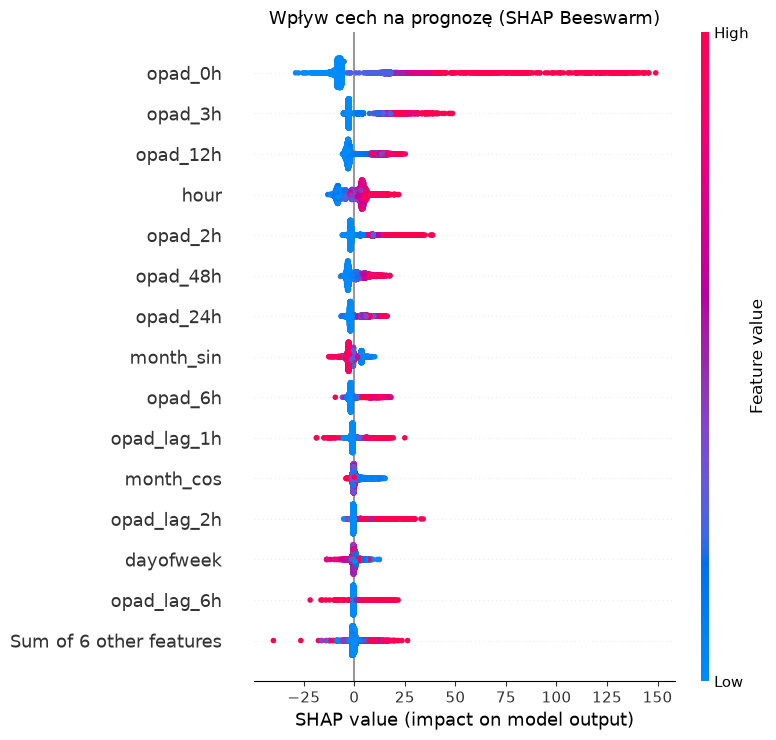

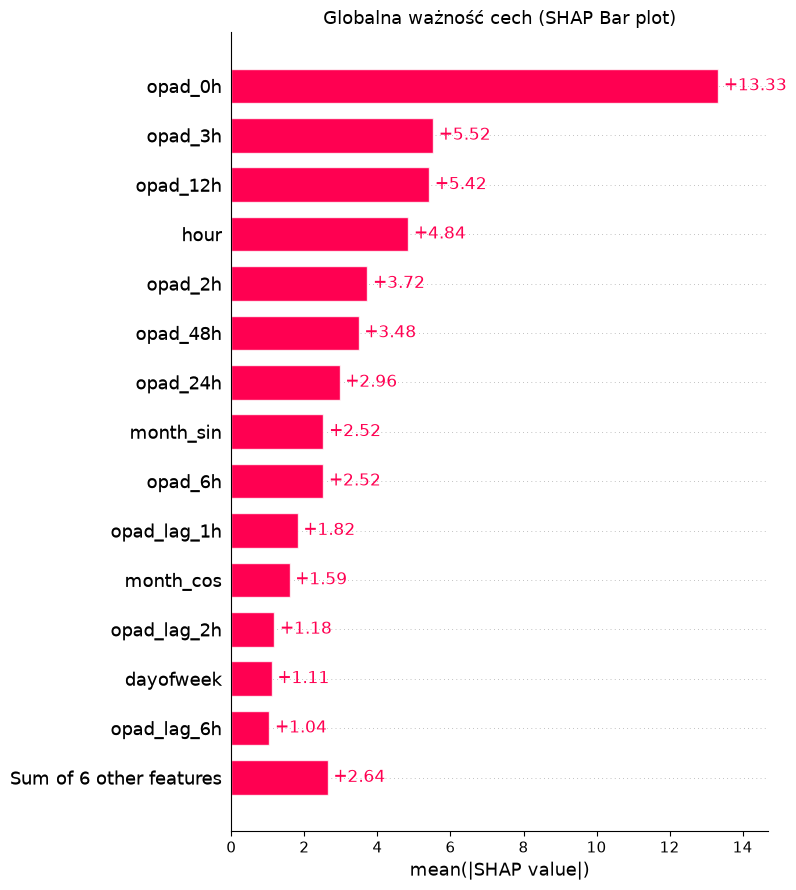

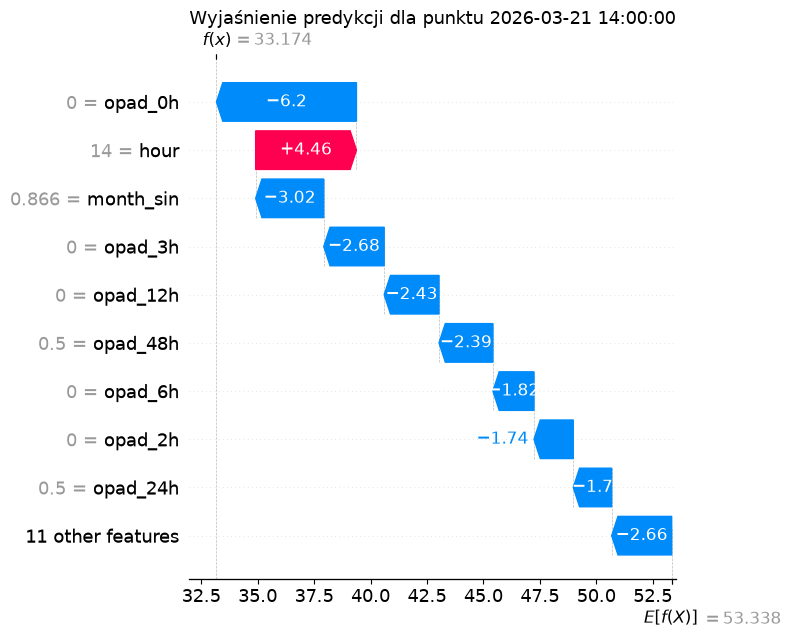

In [205]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2026-03-21 14:00:00")